In [1]:
!pip install ucimlrepo


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
from ucimlrepo import fetch_ucirepo
dry_bean = fetch_ucirepo(id=602)

In [10]:
X = dry_bean.data.features
y = dry_bean.data.targets


In [11]:
X.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [12]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (13611, 16)
Target shape: (13611, 1)


In [13]:
print("\nFeature names:")
print(X.columns.tolist())


Feature names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


In [14]:
counts = y.iloc[:, 0].value_counts().sort_index()
percentages = (counts / len(y)) * 100

class_summary = pd.DataFrame({
    "Count": counts,
    "Percentage": percentages.round(2)
})

print(class_summary)

          Count  Percentage
Class                      
BARBUNYA   1322        9.71
BOMBAY      522        3.84
CALI       1630       11.98
DERMASON   3546       26.05
HOROZ      1928       14.17
SEKER      2027       14.89
SIRA       2636       19.37


In [15]:
print("\nMissing values in features:")
print(X.isnull().sum().sum())


Missing values in features:
0


In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train70, X_test70, y_train70, y_test70 = train_test_split(
    X,
    y.iloc[:, 0],
    test_size=0.30,
    random_state=42,
    stratify=y.iloc[:, 0]
)

print("Training features:", X_train70.shape)
print("Testing features:", X_test70.shape)
print("Training labels:", y_train70.shape)
print("Testing labels:", y_test70.shape)

Training features: (9527, 16)
Testing features: (4084, 16)
Training labels: (9527,)
Testing labels: (4084,)


In [19]:
train_mean = X_train70.mean()
train_std = X_train70.std(ddof=0)

X_train_scaled = (X_train70 - train_mean) / train_std
X_test_scaled = (X_test70 - train_mean) / train_std

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nStandardized feature means:")
print(X_train_scaled.mean().round(3))

print("\nStandardized feature standard deviations:")
print(X_train_scaled.std(ddof=0).round(3))

Training data shape: (9527, 16)
Testing data shape: (4084, 16)

Standardized feature means:
Area              -0.0
Perimeter         -0.0
MajorAxisLength    0.0
MinorAxisLength   -0.0
AspectRatio        0.0
Eccentricity      -0.0
ConvexArea         0.0
EquivDiameter     -0.0
Extent             0.0
Solidity          -0.0
Roundness         -0.0
Compactness       -0.0
ShapeFactor1       0.0
ShapeFactor2      -0.0
ShapeFactor3       0.0
ShapeFactor4       0.0
dtype: float64

Standardized feature standard deviations:
Area               1.0
Perimeter          1.0
MajorAxisLength    1.0
MinorAxisLength    1.0
AspectRatio        1.0
Eccentricity       1.0
ConvexArea         1.0
EquivDiameter      1.0
Extent             1.0
Solidity           1.0
Roundness          1.0
Compactness        1.0
ShapeFactor1       1.0
ShapeFactor2       1.0
ShapeFactor3       1.0
ShapeFactor4       1.0
dtype: float64


In [20]:
class_means = {}

for c in y_train70.unique():
    X_class = X_train_scaled[y_train70 == c]
    class_means[c] = X_class.mean().to_numpy()

for c, mean_vector in class_means.items():
    print("\nClass:", c)
    print(np.round(mean_vector, 4))


Class: DERMASON
[-0.7147 -0.8888 -0.8607 -0.8152 -0.3772 -0.158  -0.7155 -0.8697  0.0819
  0.2334  0.5863  0.3138  1.0596  0.7484  0.2855  0.4184]

Class: HOROZ
[ 0.023   0.305   0.6144 -0.3982  1.7935  1.2671  0.0254  0.1324 -0.8924
 -0.3778 -1.3293 -1.6034  0.3892 -1.12   -1.533  -0.739 ]

Class: SEKER
[-0.4503 -0.5976 -0.805  -0.0109 -1.3705 -1.8072 -0.4547 -0.477   0.4539
  0.6861  1.199   1.5716 -0.2002  1.3831  1.6323  0.7474]

Class: SIRA
[-0.2792 -0.2687 -0.2369 -0.2496 -0.0516  0.1785 -0.2809 -0.2431 -0.0202
  0.1834  0.1856 -0.0418  0.131  -0.0597 -0.0738  0.0796]

Class: BARBUNYA
[ 0.5721  0.8901  0.5869  0.8414 -0.1463  0.0554  0.5804  0.7484 -0.
 -0.9139 -1.225   0.0706 -1.0667 -0.548   0.043   0.1588]

Class: CALI
[ 0.7591  0.936   1.0344  0.7517  0.6053  0.6927  0.7623  0.9461  0.1789
 -0.4597 -0.4528 -0.6955 -0.975  -1.015  -0.7093 -1.0001]

Class: BOMBAY
[ 4.1135e+00  3.4153e+00  3.1870e+00  3.8379e+00 -6.0000e-04  2.0560e-01
  4.1052e+00  3.6539e+00  5.2170e-01 -3.12

In [21]:
class_scatter = {}

for c in class_means:
    X_class = X_train_scaled[y_train70 == c].to_numpy()
    mean_vector = class_means[c]

    X_centered = X_class - mean_vector

    S_i = X_centered.T @ X_centered

    class_scatter[c] = S_i

for c, S_i in class_scatter.items():
    print("Class:", c, "| Scatter matrix shape:", S_i.shape)

Class: DERMASON | Scatter matrix shape: (16, 16)
Class: HOROZ | Scatter matrix shape: (16, 16)
Class: SEKER | Scatter matrix shape: (16, 16)
Class: SIRA | Scatter matrix shape: (16, 16)
Class: BARBUNYA | Scatter matrix shape: (16, 16)
Class: CALI | Scatter matrix shape: (16, 16)
Class: BOMBAY | Scatter matrix shape: (16, 16)


In [22]:
S_W = np.zeros((X_train_scaled.shape[1],
                X_train_scaled.shape[1]))

for c in class_scatter:
    S_W += class_scatter[c]

print("Within-class scatter matrix shape:", S_W.shape)
print("\nWithin-class scatter matrix:")
print(pd.DataFrame(
    S_W,
    index=X_train_scaled.columns,
    columns=X_train_scaled.columns
).round(3))

Within-class scatter matrix shape: (16, 16)

Within-class scatter matrix:
                    Area  Perimeter  MajorAxisLength  MinorAxisLength  \
Area             690.504    693.644          700.241          644.468   
Perimeter        693.644    810.811          800.676          654.561   
MajorAxisLength  700.241    800.676          908.776          533.503   
MinorAxisLength  644.468    654.561          533.503          872.436   
AspectRatio      224.558    395.878          730.389         -324.349   
Eccentricity     233.864    392.509          717.025         -297.328   
ConvexArea       690.132    696.103          700.123          643.637   
EquivDiameter    705.294    765.813          770.448          718.706   
Extent           -44.062   -201.020         -224.085          121.576   
Solidity          65.865   -222.740           72.241           67.164   
Roundness       -183.616   -578.755         -502.862          136.602   
Compactness     -235.428   -406.028         -736.2

In [23]:
overall_mean = X_train_scaled.mean().to_numpy()

S_B = np.zeros((X_train_scaled.shape[1],
                X_train_scaled.shape[1]))

for c in class_means:
    X_class = X_train_scaled[y_train70 == c]
    n_i = len(X_class)

    mean_difference = class_means[c] - overall_mean

    S_B += n_i * np.outer(
        mean_difference,
        mean_difference
    )

print("Between-class scatter matrix shape:", S_B.shape)
print("\nBetween-class scatter matrix:")
print(pd.DataFrame(
    S_B,
    index=X_train_scaled.columns,
    columns=X_train_scaled.columns
).round(3))

Between-class scatter matrix shape: (16, 16)

Between-class scatter matrix:
                     Area  Perimeter  MajorAxisLength  MinorAxisLength  \
Area             8836.496   8515.979         8173.974         8428.016   
Perimeter        8515.979   8716.189         8512.623         8047.274   
MajorAxisLength  8173.974   8512.623         8618.224         7341.370   
MinorAxisLength  8428.016   8047.274         7341.370         8654.564   
AspectRatio      2073.176   3283.600         4515.706          248.605   
Eccentricity     2320.387   3355.829         4461.456          509.542   
ConvexArea       8836.291   8523.059         8181.934         8426.623   
EquivDiameter    8678.553   8679.642         8392.323         8320.457   
Extent            485.557    -81.638         -606.732         1200.446   
Solidity        -1887.394  -2625.569        -2750.983        -1513.593   
Roundness       -3209.172  -4628.989        -5180.074        -2127.989   
Compactness     -2315.214  -3482.683

In [24]:

from scipy.linalg import eigh

# Step 9: Solve the generalized eigenvalue problem
eigenvalues, eigenvectors = eigh(S_B, S_W)

print("Number of eigenvalues:", len(eigenvalues))
print("Eigenvectors shape:", eigenvectors.shape)

print("\nEigenvalues in ascending order:")
print(eigenvalues)


Number of eigenvalues: 16
Eigenvectors shape: (16, 16)

Eigenvalues in ascending order:
[-2.19942955e-11 -1.06883124e-11 -1.25506110e-12 -1.03582366e-14
 -3.80887786e-17  1.58583503e-15  1.07447366e-14  2.32297728e-14
  1.58008880e-12  4.16423630e-11  4.73489563e-01  9.47078188e-01
  2.88291689e+00  3.38688731e+00  6.82204742e+00  1.71049021e+01]


In [25]:
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues_sorted = eigenvalues[sorted_indices]
eigenvectors_sorted = eigenvectors[:, sorted_indices]

print("Eigenvalues in descending order:")
print(eigenvalues_sorted)

print("\nSorted eigenvectors shape:")
print(eigenvectors_sorted.shape)

print("\nFirst six eigenvalues:")
print(eigenvalues_sorted[:6])

Eigenvalues in descending order:
[ 1.71049021e+01  6.82204742e+00  3.38688731e+00  2.88291689e+00
  9.47078188e-01  4.73489563e-01  4.16423630e-11  1.58008880e-12
  2.32297728e-14  1.07447366e-14  1.58583503e-15 -3.80887786e-17
 -1.03582366e-14 -1.25506110e-12 -1.06883124e-11 -2.19942955e-11]

Sorted eigenvectors shape:
(16, 16)

First six eigenvalues:
[17.10490211  6.82204742  3.38688731  2.88291689  0.94707819  0.47348956]


In [26]:

# Step 11: Select the top two LDA components

n_components = 2

W = eigenvectors_sorted[:, :n_components]

print("Projection matrix shape:", W.shape)
print("\nProjection matrix W:")
print(W)


Projection matrix shape: (16, 2)

Projection matrix W:
[[ 2.81449745e-01 -2.18600027e-01]
 [ 1.17242714e-01 -8.20257211e-02]
 [ 5.06564572e-01 -3.38046322e-01]
 [ 3.22771221e-01 -1.18470834e-01]
 [-9.43648022e-02  1.25632057e-02]
 [-2.27324317e-03  3.85048611e-02]
 [-2.48966481e-01  1.59505651e-01]
 [-1.01653373e+00  5.43501254e-01]
 [-5.23844314e-04  2.13376482e-04]
 [-1.69043507e-03  3.61344075e-03]
 [ 1.88381347e-02 -1.72038960e-02]
 [-1.19153140e-01 -4.55148127e-01]
 [-2.49325502e-02 -5.01289204e-02]
 [-5.47457886e-02  9.11071458e-02]
 [ 8.02687942e-02  3.53350397e-01]
 [ 9.61217289e-03 -7.66972699e-03]]


In [27]:
# Transform training data
X_train_lda = X_train_scaled.to_numpy() @ W

# Transform testing data
X_test_lda = X_test_scaled.to_numpy() @ W

print("Transformed training data shape:", X_train_lda.shape)
print("Transformed testing data shape:", X_test_lda.shape)

Transformed training data shape: (9527, 2)
Transformed testing data shape: (4084, 2)


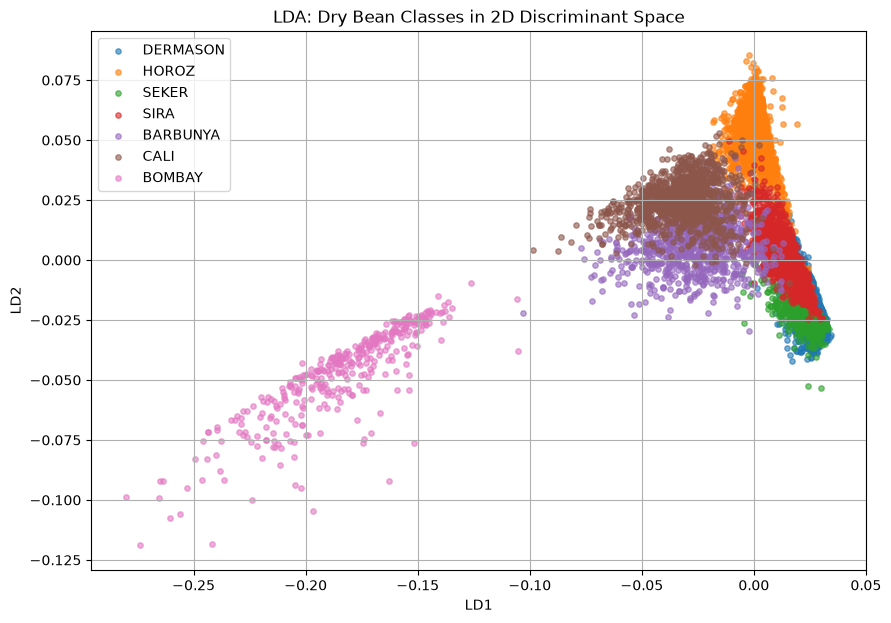

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for c in y_train70.unique():
    mask = (y_train70 == c).to_numpy()

    plt.scatter(
        X_train_lda[mask, 0],
        X_train_lda[mask, 1],
        label=c,
        alpha=0.6,
        s=15
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA: Dry Bean Classes in 2D Discriminant Space")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
import numpy as np
from sklearn.metrics import accuracy_score

# Calculate the centroid of each class in LDA space
centroids = {}

for c in y_train70.unique():
    mask = (y_train70 == c).to_numpy()
    centroids[c] = X_train_lda[mask].mean(axis=0)

# Predict the class of each test sample
y_pred = []

for sample in X_test_lda:
    distances = {}

    for c in centroids:
        distances[c] = np.linalg.norm(sample - centroids[c])

    predicted_class = min(distances, key=distances.get)
    y_pred.append(predicted_class)

# Evaluate accuracy
accuracy = accuracy_score(y_test70, y_pred)

print("Nearest-centroid accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Nearest-centroid accuracy: 0.763
Accuracy percentage: 76.3 %


In [30]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Confusion matrix
cm = confusion_matrix(y_test70, y_pred, labels=y_train70.unique())

print("Class order:")
print(y_train70.unique())

print("\nConfusion Matrix:")
print(cm)

# Precision, recall, and F1-score for each class
print("\nClassification Report:")
print(classification_report(y_test70, y_pred, zero_division=0))

Class order:
<StringArray>
['DERMASON', 'HOROZ', 'SEKER', 'SIRA', 'BARBUNYA', 'CALI', 'BOMBAY']
Length: 7, dtype: str

Confusion Matrix:
[[544   0 409 111   0   0   0]
 [  1 556   0  16   0   5   0]
 [ 75   0 504  29   0   0   0]
 [119  11   2 657   2   0   0]
 [  1   5   4  33 277  77   0]
 [  0  14   1   4  49 421   0]
 [  0   0   0   0   0   0 157]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.84      0.70      0.76       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.84      0.86      0.85       489
    DERMASON       0.74      0.51      0.60      1064
       HOROZ       0.95      0.96      0.96       578
       SEKER       0.55      0.83      0.66       608
        SIRA       0.77      0.83      0.80       791

    accuracy                           0.76      4084
   macro avg       0.81      0.81      0.80      4084
weighted avg       0.78      0.76      0.76      4084



In [31]:
from sklearn.metrics import accuracy_score
import numpy as np

component_results = []

for k in range(1, 7):

    # Select the first k eigenvectors
    W_k = eigenvectors_sorted[:, :k]

    # Transform training and testing data
    X_train_k = X_train_scaled.to_numpy() @ W_k
    X_test_k = X_test_scaled.to_numpy() @ W_k

    # Calculate training centroid for each class
    centroids_k = {}

    for c in y_train70.unique():
        mask = (y_train70 == c).to_numpy()
        centroids_k[c] = X_train_k[mask].mean(axis=0)

    # Predict test classes
    predictions_k = []

    for sample in X_test_k:
        distances = {
            c: np.linalg.norm(sample - centroids_k[c])
            for c in centroids_k
        }

        predictions_k.append(min(distances, key=distances.get))

    # Calculate accuracy
    acc = accuracy_score(y_test70, predictions_k)
    component_results.append((k, acc))

# Display results
for k, acc in component_results:
    print(f"{k} component(s): {acc:.4f} ({acc * 100:.2f}%)")

1 component(s): 0.6097 (60.97%)
2 component(s): 0.7630 (76.30%)
3 component(s): 0.9062 (90.62%)
4 component(s): 0.9101 (91.01%)
5 component(s): 0.9121 (91.21%)
6 component(s): 0.9033 (90.33%)


### Effect of the Number of LDA Components

The nearest-centroid classifier was evaluated using 1 to 6 LDA components. Test accuracy increased from 60.97% with one component to 76.30% with two components and 90.62% with three components. The highest accuracy was 91.21% with five components. Accuracy decreased slightly to 90.33% with six components.

These results indicate that retaining additional discriminant directions preserves useful class-separation information that is lost in the two-dimensional representation. Although two components are useful for visualization, five components performed best for classification with the nearest-centroid method. Adding components does not necessarily improve accuracy because the LDA projection criterion and nearest-centroid classification objective are different.

Transformed data shape: (9527, 3)


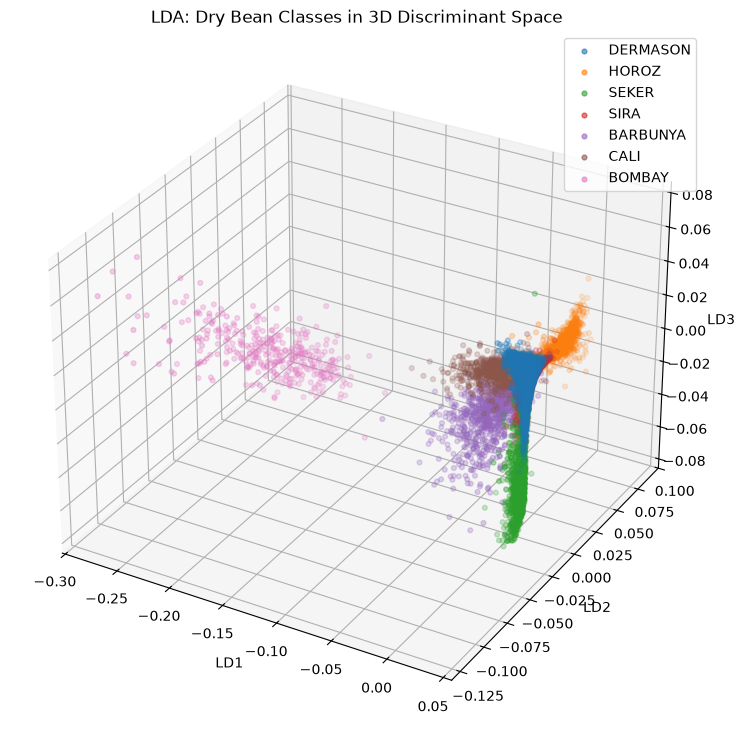

In [32]:
import matplotlib.pyplot as plt

# Select the first 3 LDA components
W_3 = eigenvectors_sorted[:, :3]

# Transform the training data into 3D LDA space
X_train_lda_3 = X_train_scaled.to_numpy() @ W_3

print("Transformed data shape:", X_train_lda_3.shape)

# Create a 3D scatter plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

for c in y_train70.unique():
    mask = (y_train70 == c).to_numpy()

    ax.scatter(
        X_train_lda_3[mask, 0],
        X_train_lda_3[mask, 1],
        X_train_lda_3[mask, 2],
        label=c,
        alpha=0.6,
        s=12
    )

ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.set_zlabel("LD3")
ax.set_title("LDA: Dry Bean Classes in 3D Discriminant Space")
ax.legend()
plt.show()

In [33]:
from sklearn.model_selection import train_test_split

X_train80, X_test80, y_train80, y_test80 = train_test_split(
    X,
    y.iloc[:, 0],
    test_size=0.20,
    random_state=42,
    stratify=y.iloc[:, 0]
)

print("Training features:", X_train80.shape)
print("Testing features:", X_test80.shape)

print("\nTraining samples per class:")
print(y_train80.value_counts())

print("\nTesting samples per class:")
print(y_test80.value_counts())

Training features: (10888, 16)
Testing features: (2723, 16)

Training samples per class:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1542
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64

Testing samples per class:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       386
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


In [34]:
# Calculate mean and standard deviation from training data only
mean80 = X_train80.mean()
std80 = X_train80.std(ddof=0)

# Standardize training data
X_train80_scaled = (X_train80 - mean80) / std80

# Standardize testing data using training statistics
X_test80_scaled = (X_test80 - mean80) / std80

print("Training data shape:", X_train80_scaled.shape)
print("Testing data shape:", X_test80_scaled.shape)

print("\nTraining feature means (first 5):")
print(X_train80_scaled.mean().head())

print("\nTraining feature standard deviations (first 5):")
print(X_train80_scaled.std(ddof=0).head())

Training data shape: (10888, 16)
Testing data shape: (2723, 16)

Training feature means (first 5):
Area               1.220348e-16
Perimeter         -1.089830e-15
MajorAxisLength   -1.938200e-16
MinorAxisLength   -3.050870e-16
AspectRatio       -7.374295e-17
dtype: float64

Training feature standard deviations (first 5):
Area               1.0
Perimeter          1.0
MajorAxisLength    1.0
MinorAxisLength    1.0
AspectRatio        1.0
dtype: float64


In [35]:
import numpy as np

# Step 1: Calculate the mean vector for each class
class_means80 = {}

for c in y_train80.unique():
    X_class = X_train80_scaled[y_train80 == c]
    class_means80[c] = X_class.mean().to_numpy()

# Step 2: Calculate within-class scatter
n_features = X_train80_scaled.shape[1]

S_W80 = np.zeros((n_features, n_features))

for c in class_means80:
    X_class = X_train80_scaled[y_train80 == c].to_numpy()
    mean_vector = class_means80[c]

    X_centered = X_class - mean_vector
    S_W80 += X_centered.T @ X_centered

# Step 3: Calculate between-class scatter
overall_mean80 = X_train80_scaled.mean().to_numpy()

S_B80 = np.zeros((n_features, n_features))

for c in class_means80:
    X_class = X_train80_scaled[y_train80 == c]
    n_i = len(X_class)

    mean_difference = class_means80[c] - overall_mean80

    S_B80 += n_i * np.outer(mean_difference, mean_difference)

# Display results
print("Number of classes:", len(class_means80))
print("Within-class scatter shape:", S_W80.shape)
print("Between-class scatter shape:", S_B80.shape)

Number of classes: 7
Within-class scatter shape: (16, 16)
Between-class scatter shape: (16, 16)


In [36]:
from scipy.linalg import eigh

# Solve the generalized eigenvalue problem
eigenvalues80, eigenvectors80 = eigh(S_B80, S_W80)

# Sort eigenvalues in descending order
sorted_indices80 = np.argsort(eigenvalues80)[::-1]

eigenvalues80_sorted = eigenvalues80[sorted_indices80]
eigenvectors80_sorted = eigenvectors80[:, sorted_indices80]

print("Eigenvalues in descending order:")
print(eigenvalues80_sorted)

# Select the first 5 discriminant directions
W80 = eigenvectors80_sorted[:, :5]

print("\nProjection matrix shape:", W80.shape)

Eigenvalues in descending order:
[ 1.73093214e+01  6.95494700e+00  3.35366237e+00  2.90277739e+00
  9.68076363e-01  4.73454119e-01  7.71325606e-11  1.68785281e-12
  3.94851641e-13  5.51240573e-14  1.00683004e-14 -2.83221818e-17
 -1.15114305e-15 -5.47817229e-14 -6.54627090e-13 -6.04035941e-11]

Projection matrix shape: (16, 5)


In [37]:
# Transform training data into 5-dimensional LDA space
X_train80_lda = X_train80_scaled.to_numpy() @ W80

# Transform testing data using the same projection
X_test80_lda = X_test80_scaled.to_numpy() @ W80

print("Transformed training data shape:", X_train80_lda.shape)
print("Transformed testing data shape:", X_test80_lda.shape)

Transformed training data shape: (10888, 5)
Transformed testing data shape: (2723, 5)


In [38]:
from sklearn.metrics import accuracy_score
import numpy as np

# Calculate centroid of each class using training data
centroids80 = {}

for c in y_train80.unique():
    mask = (y_train80 == c).to_numpy()
    centroids80[c] = X_train80_lda[mask].mean(axis=0)

# Predict test classes
y_pred80 = []

for sample in X_test80_lda:
    distances = {}

    for c in centroids80:
        distances[c] = np.linalg.norm(sample - centroids80[c])

    predicted_class = min(distances, key=distances.get)
    y_pred80.append(predicted_class)

# Evaluate accuracy
accuracy80 = accuracy_score(y_test80, y_pred80)

print("80:20 split - Nearest-centroid accuracy:", round(accuracy80, 4))
print("Accuracy percentage:", round(accuracy80 * 100, 2), "%")

80:20 split - Nearest-centroid accuracy: 0.9093
Accuracy percentage: 90.93 %


### Comparison of 70:30 and 80:20 Train-Test Splits

Using five LDA components and a nearest-centroid classifier, the 70:30 split achieved 91.21% test accuracy, while the 80:20 split achieved 90.93%. The difference was 0.28 percentage points.

Despite having more training samples, the 80:20 split did not produce higher accuracy in this experiment. This shows that test accuracy depends not only on training-set size but also on the samples selected and the resulting LDA projection and class centroids. The results are similar, and neither split can be considered universally superior based on this single experiment.

In [39]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix (80:20):")
print(confusion_matrix(y_test80, y_pred80, labels=y_train80.unique()))

print("\nClassification Report (80:20):")
print(classification_report(y_test80, y_pred80, zero_division=0))

Confusion Matrix (80:20):
[[378   0   0  18   9   1   0]
 [  0 353  14  16   2   1   0]
 [  2   5 312   4   0   3   0]
 [  3   6   0 472  45   1   0]
 [ 11   0   0  60 638   0   0]
 [  3   1  27  15   0 219   0]
 [  0   0   0   0   0   0 104]]

Classification Report (80:20):
              precision    recall  f1-score   support

    BARBUNYA       0.97      0.83      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.88      0.96      0.92       326
    DERMASON       0.92      0.90      0.91       709
       HOROZ       0.97      0.91      0.94       386
       SEKER       0.95      0.93      0.94       406
        SIRA       0.81      0.90      0.85       527

    accuracy                           0.91      2723
   macro avg       0.93      0.92      0.92      2723
weighted avg       0.91      0.91      0.91      2723



In [40]:
from sklearn.metrics import accuracy_score
import numpy as np

component_results80 = []

for k in range(1, 7):

    # Select the first k eigenvectors
    W_k = eigenvectors80_sorted[:, :k]

    # Transform training and testing data
    X_train_k = X_train80_scaled.to_numpy() @ W_k
    X_test_k = X_test80_scaled.to_numpy() @ W_k

    # Calculate class centroids
    centroids_k = {}

    for c in y_train80.unique():
        mask = (y_train80 == c).to_numpy()
        centroids_k[c] = X_train_k[mask].mean(axis=0)

    # Predict test classes
    predictions_k = []

    for sample in X_test_k:
        distances = {
            c: np.linalg.norm(sample - centroids_k[c])
            for c in centroids_k
        }

        predictions_k.append(min(distances, key=distances.get))

    # Calculate accuracy
    acc = accuracy_score(y_test80, predictions_k)
    component_results80.append((k, acc))

for k, acc in component_results80:
    print(f"{k} component(s): {acc:.4f} ({acc * 100:.2f}%)")

1 component(s): 0.6192 (61.92%)
2 component(s): 0.7701 (77.01%)
3 component(s): 0.9097 (90.97%)
4 component(s): 0.9089 (90.89%)
5 component(s): 0.9093 (90.93%)
6 component(s): 0.9027 (90.27%)


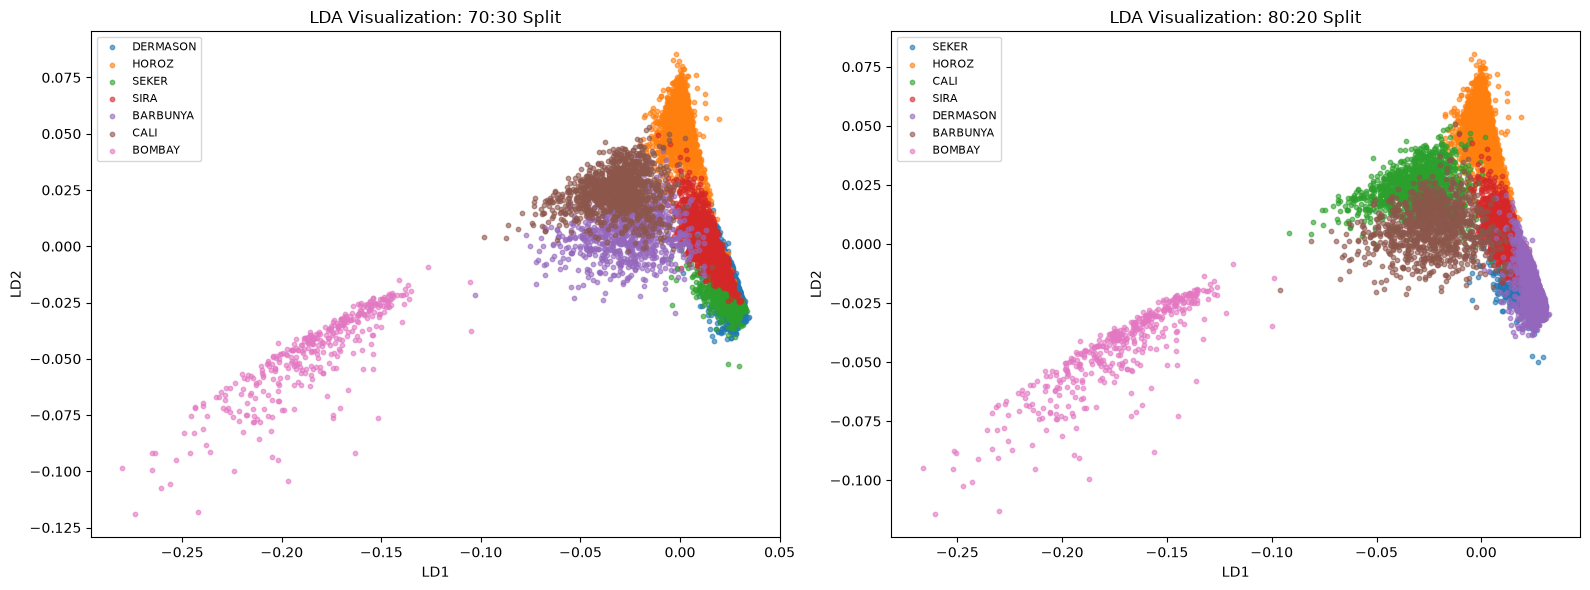

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 70:30 split
for c in y_train70.unique():
    mask = (y_train70 == c).to_numpy()

    axes[0].scatter(
        X_train_lda[mask, 0],
        X_train_lda[mask, 1],
        label=c,
        alpha=0.6,
        s=10
    )

axes[0].set_title("LDA Visualization: 70:30 Split")
axes[0].set_xlabel("LD1")
axes[0].set_ylabel("LD2")
axes[0].legend(fontsize=8)

# 80:20 split: calculate the first 2 components
W80_2 = eigenvectors80_sorted[:, :2]
X_train80_lda_2 = X_train80_scaled.to_numpy() @ W80_2

for c in y_train80.unique():
    mask = (y_train80 == c).to_numpy()

    axes[1].scatter(
        X_train80_lda_2[mask, 0],
        X_train80_lda_2[mask, 1],
        label=c,
        alpha=0.6,
        s=10
    )

axes[1].set_title("LDA Visualization: 80:20 Split")
axes[1].set_xlabel("LD1")
axes[1].set_ylabel("LD2")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

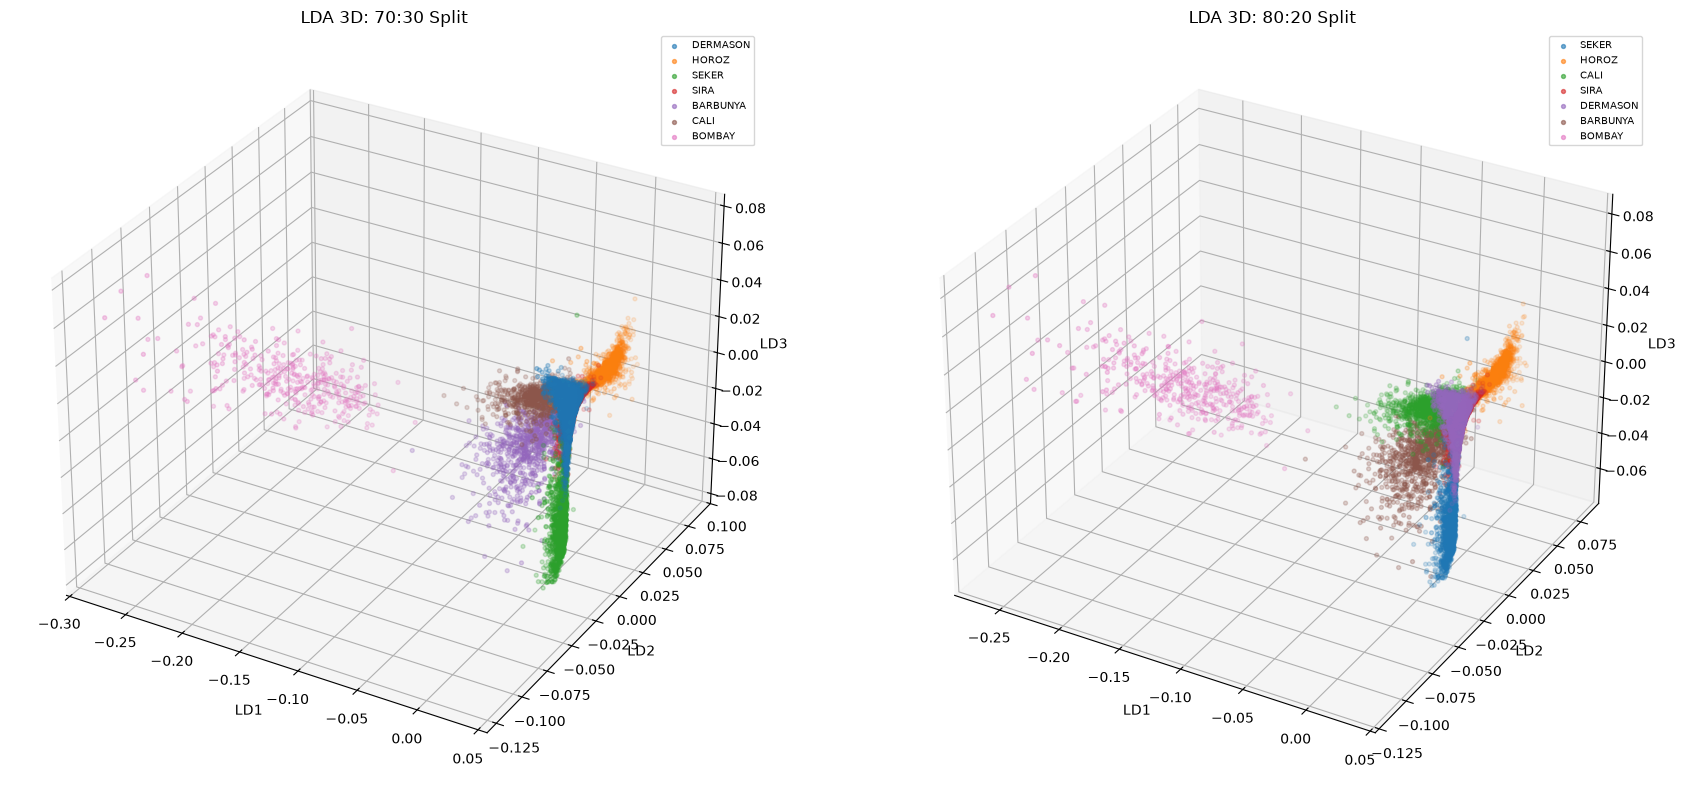

In [42]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(18, 8))

# 70:30 split: first 3 LDA components
ax1 = fig.add_subplot(121, projection="3d")

for c in y_train70.unique():
    mask = (y_train70 == c).to_numpy()

    ax1.scatter(
        X_train_lda_3[mask, 0],
        X_train_lda_3[mask, 1],
        X_train_lda_3[mask, 2],
        label=c,
        alpha=0.6,
        s=8
    )

ax1.set_title("LDA 3D: 70:30 Split")
ax1.set_xlabel("LD1")
ax1.set_ylabel("LD2")
ax1.set_zlabel("LD3")
ax1.legend(fontsize=7)


# 80:20 split: first 3 LDA components
W80_3 = eigenvectors80_sorted[:, :3]
X_train80_lda_3 = X_train80_scaled.to_numpy() @ W80_3

ax2 = fig.add_subplot(122, projection="3d")

for c in y_train80.unique():
    mask = (y_train80 == c).to_numpy()

    ax2.scatter(
        X_train80_lda_3[mask, 0],
        X_train80_lda_3[mask, 1],
        X_train80_lda_3[mask, 2],
        label=c,
        alpha=0.6,
        s=8
    )

ax2.set_title("LDA 3D: 80:20 Split")
ax2.set_xlabel("LD1")
ax2.set_ylabel("LD2")
ax2.set_zlabel("LD3")
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()